# Lab 1A: Image Processing Fundamentals
**Course:** 0135326 - Computer Vision
**Instructor:** Dr. Akram Fatayer
---

## 1. Introduction & Learning Objectives

Welcome to your first lab in Computer Vision! The goal of this lab is to get comfortable with the fundamental building blocks of image processing. We will move from the theory you learned in Module 1 to hands-on practice. By the end of this lab, you will be able to:

1. Load, display, and save images using Python.
2. Understand and manipulate image properties like pixels and dimensions.
3. Convert images between different color spaces (RGB, Grayscale, HSV).
4. Calculate and interpret image histograms.
5. Perform basic point operations like adjusting brightness and contrast.
6. Apply fundamental image filtering techniques using convolution (blurring, sharpening).

This lab is designed to be completed within a 1-hour guided session. You will fill in missing code blocks and experiment with the parameters to solidify your understanding.

## 2. Setup: Importing Libraries

First, we need to import the necessary Python libraries. We will primarily use:
- OpenCV (cv2): The industry-standard library for computer vision tasks.
- NumPy: For efficient numerical operations, as images are just matrices of numbers.
- Matplotlib: For displaying images and plots within our notebook.

In [1]:
# Import the necessary libraries
import cv2
import numpy as np
from matplotlib import pyplot as plt

# This command helps to display plots and images directly in the notebook
%matplotlib inline

## 3. Loading and Displaying Images

Our first step is to load an image from a file into our program. We will use a standard sample image for this part. OpenCV's cv2.imread() function is used for this purpose.

Important Note: OpenCV loads images in BGR (Blue, Green, Red) format by default, while Matplotlib expects images in RGB (Red, Green, Blue) format. We must convert the color space before displaying to avoid incorrect colors.

In [15]:
# We need a sample image. Let's download one.
# The ! allows us to run a shell command from within the notebook.
!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.png -O lena.png

# Load the image from the file
image_bgr = cv2.imread('/content/Lenna_(test_image).png')

# Check the type and shape of the loaded image
print(f'Image Type: {type(image_bgr)}')
print(f'Image Shape (Height, Width, Channels): {image_bgr.shape}')

--2026-10-26 13:08:30--  https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.png
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-10-26 13:08:30 ERROR 404: Not Found.

Image Type: <class 'numpy.ndarray'>
Image Shape (Height, Width, Channels): (512, 512, 3)


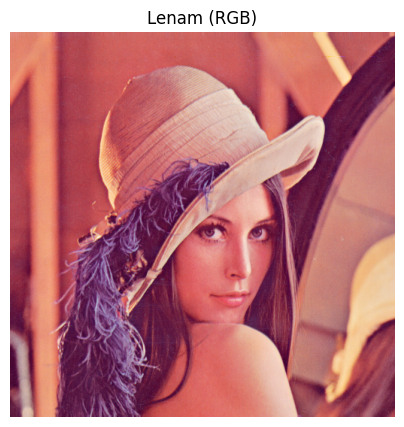

In [16]:
# Convert the image from BGR to RGB for displaying with Matplotlib
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

# Display the image
plt.figure(figsize=(5,5))
plt.imshow(image_rgb)
plt.title('Lenam (RGB)')
plt.axis('off')
plt.show()

### Exercise 1: Your Turn!

Download another image and display it. You can use this URL for a coins image: https://raw.githubusercontent.com/opencv/opencv/master/samples/data/coins.png

In [17]:
# --- YOUR CODE HERE ---
# 1. Download the coins.png image using !wget

# 2. Load the image using cv2.imread()

# 3. Convert it from BGR to RGB

# 4. Display the image with a title using plt.imshow() and plt.title()

# --- END OF YOUR CODE ---

## 4. Color Spaces & Histograms

Images can be represented in different color spaces, each useful for different tasks. We will explore Grayscale and HSV.

A histogram is a graph that shows the distribution of pixel intensities in an image. It is a powerful tool for understanding the brightness, contrast, and color balance of an image.

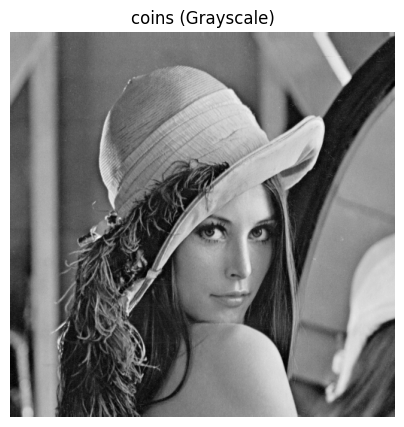

In [18]:
# Convert the original image to Grayscale
image_gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)

# Display the grayscale image
plt.figure(figsize=(5,5))
plt.imshow(image_gray, cmap='gray')
plt.title('coins (Grayscale)')
plt.axis('off')
plt.show()

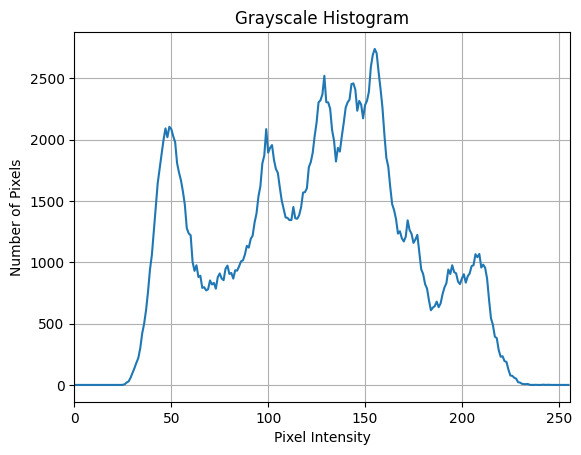

In [19]:
# Calculate and plot the histogram for the grayscale image
# cv2.calcHist([image], [channel], mask, [histSize], [ranges])
hist_gray = cv2.calcHist([image_gray], [0], None, [256], [0, 256])

plt.figure()
plt.title('Grayscale Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Number of Pixels')
plt.plot(hist_gray)
plt.xlim([0, 256])
plt.grid(True)
plt.show()

### Exercise 2: Color Histogram

Calculate and plot the histogram for each channel (Red, Green, Blue) of the original color image (image_rgb).

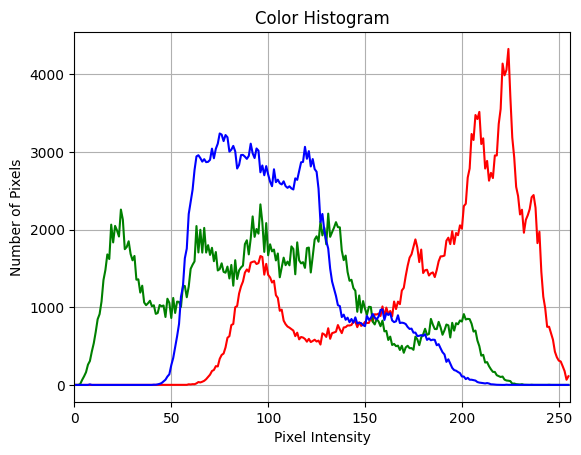

In [31]:
plt.figure()
plt.title('Color Histogram')
plt.xlabel('Pixel Intensity')
plt.ylabel('Number of Pixels')

colors = ('r', 'g', 'b')
# The image_rgb has 3 channels. We need to loop through them.
for i, color in enumerate(colors):
    # --- YOUR CODE HERE ---
    # 1. Calculate the histogram for the i-th channel of image_rgb
    # Hint: Use cv2.calcHist([image_rgb], [i], ...)
    hist = cv2.calcHist([image_rgb], [i], None, [256], [0, 256])

    # 2. Plot the histogram with the correct color
    plt.plot(hist, color=color)
    # --- END OF YOUR CODE ---

plt.xlim([0, 256])
plt.grid(True)
plt.show()

## 5. Image Filtering (Convolution)

Filtering is one of the most fundamental operations in image processing. It involves applying a kernel (a small matrix) to an image to achieve effects like blurring, sharpening, or edge detection. This operation is called convolution.

We will experiment with a few common filters.

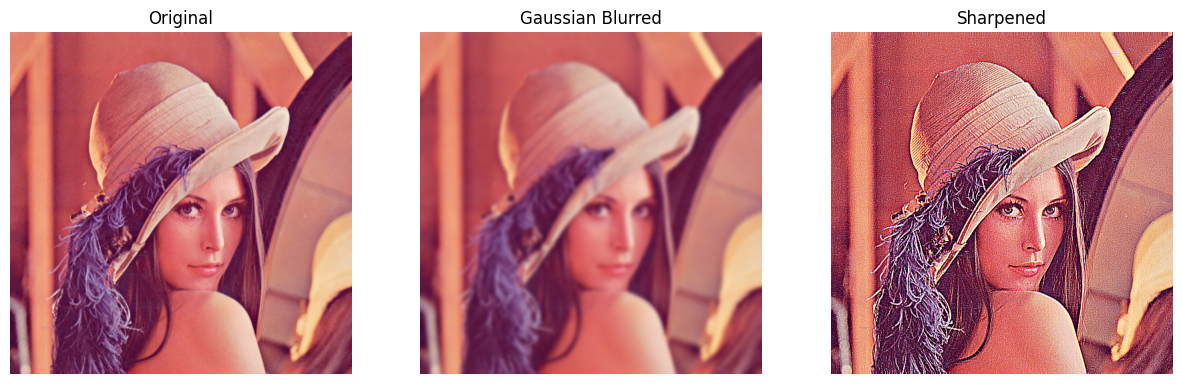

In [32]:
# Blurring with a Gaussian Filter
# This is very common for noise reduction.
# The (15, 15) is the kernel size. It must be an odd number.
image_blurred = cv2.GaussianBlur(image_rgb, (15, 15), 0)

# Sharpening Filter
# We can create a custom kernel to sharpen the image.
sharpen_kernel = np.array([[-1, -1, -1],
                           [-1,  9, -1],
                           [-1, -1, -1]])
image_sharpened = cv2.filter2D(image_rgb, -1, sharpen_kernel)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image_rgb)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(image_blurred)
plt.title('Gaussian Blurred')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(image_sharpened)
plt.title('Sharpened')
plt.axis('off')

plt.show()

### Exercise 3: Experiment with Blurring

In the code block below, apply a Gaussian blur with three different kernel sizes: (5, 5), (25, 25), and (51, 51). Display all three results side-by-side. What do you observe as the kernel size increases?

In [33]:
# --- YOUR CODE HERE ---
# 1. Apply Gaussian blur with kernel size (5, 5)

# 2. Apply Gaussian blur with kernel size (25, 25)

# 3. Apply Gaussian blur with kernel size (51, 51)

# 4. Display all three blurred images and the original in a 1x4 subplot

# --- END OF YOUR CODE ---

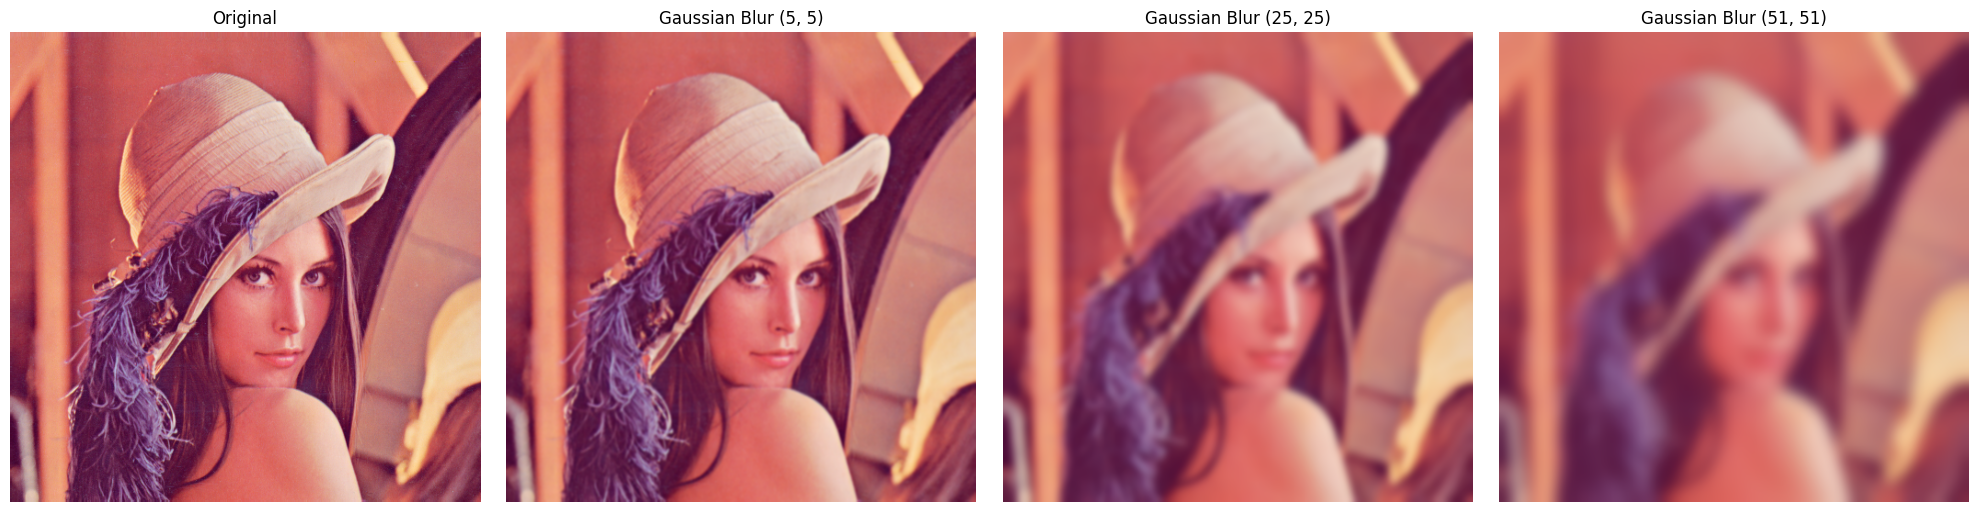

In [34]:

# --- YOUR CODE HERE ---

# 1. Apply Gaussian blur with kernel size (5, 5)
image_blurred_5 = cv2.GaussianBlur(image_rgb, (5, 5), 0)

# 2. Apply Gaussian blur with kernel size (25, 25)
image_blurred_25 = cv2.GaussianBlur(image_rgb, (25, 25), 0)

# 3. Apply Gaussian blur with kernel size (51, 51)
image_blurred_51 = cv2.GaussianBlur(image_rgb, (51, 51), 0)

# 4. Display all three blurred images and the original in a 1x4 subplot
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(image_rgb)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(image_blurred_5)
plt.title('Gaussian Blur (5, 5)')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(image_blurred_25)
plt.title('Gaussian Blur (25, 25)')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(image_blurred_51)
plt.title('Gaussian Blur (51, 51)')
plt.axis('off')

plt.tight_layout()
plt.show()

# --- END OF YOUR CODE ---

## 6. Conclusion & Submission

Congratulations on completing your first computer vision lab! You have learned how to handle images as data, inspect their properties, and apply fundamental processing techniques.

### Deliverables
1. Completed Notebook: Ensure all your code cells for the exercises are filled in and run without errors.
2. Brief Reflection: In the markdown cell below, write a short (1-2 paragraph) reflection. What was the most interesting or surprising thing you learned? How do you think these basic techniques could be used in a real-world application?

### How to Submit
1. Go to File -> Download -> Download .ipynb
2. Upload the downloaded .ipynb file to the LMS assignment page.

### Reflection

Write your reflection here (1-2 paragraphs):